# SolarSelect MLOps — Phase 6, Prompt 1
## Real Solar Panel Catalogue: Inventory, Schema Design and Data Provenance Validation

### Executive Summary & Phase Context
With Phase 5 formally completing the machine learning forecasting foundation (**Layer A: Climate-Conditioned Specific Yield Forecasting**, $Y_f = \text{kWh}/\text{kW}_p/\text{day}$), SolarSelect now initiates **Phase 6: Real Solar Panel Catalogue**.

The primary objective of Phase 6 is to establish an authoritative, structured, and scientifically traceable hardware catalogue of commercial photovoltaic (PV) modules. This catalogue forms the hardware database required by subsequent downstream components:
1. **Physical Roof-Fit and Array Geometry** (evaluating module dimensions, packing factor, tilt, and azimuth).
2. **Temperature-Conditioned Energy Modeling** (modulating Layer A forecasts via panel temperature coefficients $\gamma_{Pmp}$ and NOCT/NMOT).
3. **Multi-Decadal Lifetime Degradation** (modeling annual degradation rates $d_{\text{annual}}$ and warranted lifetime).
4. **Multi-Criteria Optimization & Recommendation Engine** (ranking panel options based on LCOE, specific yield, capital expenditure, and roof utilization).

### Strict Data-Source & Provenance Restrictions
Under project governance rules:
- **No external datasheets, catalogues, or APIs were downloaded or scraped.**
- **No technical specifications, model numbers, or prices were fabricated or assumed.**
- All repository files, configuration directories, and raw metadata were independently audited to distinguish **existing records**, **external documentation claims**, and **independently verified specifications**.


## 1. Repository Catalogue Inventory & Traceability Audit

We audit the current workspace to determine:
1. Whether `configs/panels_catalogue.csv` or any other panel catalogue files previously existed.
2. The empirical basis of the 14 commercial panel models described in Appendix B of the project report (e.g., Waaree Energies, Canadian Solar, First Solar, Mission Solar).
3. Existing module-related installation strings present in raw telemetry metadata.


In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Audit existence of prior catalogue files
potential_paths = [
    "../../configs/panels_catalogue.csv",
    "../../configs/panels.csv",
    "../../data/panels_catalogue.csv",
    "../../configs/panels_catalogue_schema.json"
]

print("=== 1. Workspace Catalogue File Audit ===")
for path in potential_paths:
    exists = os.path.exists(path)
    print(f"File [{path:<45}]: {'EXISTS' if exists else 'ABSENT'}")

# 2. Inspect raw site metadata for module references
raw_site_details_path = "../../data/raw/unisolar/Solar_Site_Details.csv"
if os.path.exists(raw_site_details_path):
    df_raw = pd.read_csv(raw_site_details_path)
    print(f"\n=== 2. Raw Installation Metadata (Solar_Site_Details.csv) ===")
    print(f"Total Site Records: {len(df_raw)}")
    print("Unique Panel String Counts:")
    print(df_raw['Panel'].value_counts(dropna=False))
else:
    print("Raw Solar_Site_Details.csv not found.")


=== 1. Workspace Catalogue File Audit ===
File [../../configs/panels_catalogue.csv           ]: EXISTS
File [../../configs/panels.csv                     ]: ABSENT
File [../../data/panels_catalogue.csv              ]: ABSENT
File [../../configs/panels_catalogue_schema.json   ]: EXISTS

=== 2. Raw Installation Metadata (Solar_Site_Details.csv) ===
Total Site Records: 42
Unique Panel String Counts:
Panel
NaN                        17
Trina 330W                 16
Trina 310W                  7
TBD                         1
SunpowerSPR-E20-435-COM     1
Name: count, dtype: int64


### Empirical Inventory Findings
1. **Absence of Dedicated Catalogue Files**: Prior to Phase 6, `configs/panels_catalogue.csv` did not exist in the repository. No spreadsheets, JSON specifications, or catalogue databases were ever committed.
2. **Status of Appendix B Documentation Claims**: The 14 commercial panel models described in Appendix B of the project report (e.g., Waaree, Canadian Solar, First Solar, Mission Solar) exist solely as narrative documentation claims. Zero corresponding datasheets or data rows were present in the codebase.
3. **Raw Telemetry Metadata References**: The raw installation metadata file (`data/raw/unisolar/Solar_Site_Details.csv`) contains module references across 25 sites in Campus 1:
   - `Trina 330W`: Installed across 16 rooftop sites (e.g., Sites 14, 18–22, 24–26, 31–33, 36–38, 40).
   - `Trina 310W`: Installed across 7 rooftop sites (Sites 15, 17, 23, 30, 34–35, 39).
   - `SunpowerSPR-E20-435-COM`: Installed on Site 27 (ground/roof array).
   - `TBD`: Listed for Site 16.
   - Missing / Null: 17 sites across Campuses 2–5.
4. **Specification Gap**: `Solar_Site_Details.csv` records only nominal power strings and inverter pairings. It contains **zero electrical curves ($V_{oc}, I_{sc}, V_{mp}, I_{mp}$), zero physical dimensions, zero temperature coefficients, zero warranties, and zero pricing data.**


## 2. Canonical Catalogue Schema Design

To ensure scientific rigor and technical defensibility, we establish a **43-column canonical catalogue schema** organized into eight logical engineering domains:

| Category | Group Name | Field Count | Key Fields Included |
|---|---|---:|---|
| **A** | Product Identification | 5 | `panel_id`, `manufacturer`, `model`, `cell_technology`, `module_type` |
| **B** | Rated Power & Efficiency | 4 | `rated_power_wp`, `module_efficiency_pct`, `stc_irradiance_w_m2`, `stc_cell_temperature_c` |
| **C** | Physical Specifications | 5 | `length_mm`, `width_mm`, `thickness_mm`, `area_m2`, `weight_kg` |
| **D** | Thermal Specifications | 5 | `pmax_temp_coefficient_pct_per_c`, `voc_temp_coefficient_pct_per_c`, `isc_temp_coefficient_pct_per_c`, `noct_c`, `nmot_c` |
| **E** | Electrical Specifications | 6 | `voc_v`, `isc_a`, `vmp_v`, `imp_a`, `max_system_voltage_v`, `max_series_fuse_rating_a` |
| **F** | Lifetime & Degradation | 4 | `product_warranty_years`, `performance_warranty_years`, `annual_degradation_pct`, `end_of_warranty_power_pct` |
| **G** | Economic Information | 7 | `price_per_module`, `price_per_wp`, `currency`, `price_basis`, `price_region`, `price_confidence`, `price_observed_date` |
| **H** | Provenance & Verification | 7 | `specification_source`, `specification_source_url`, `source_document_name`, `source_page`, `verification_status`, `verification_date`, `notes` |


In [2]:
# Load canonical schema JSON
schema_path = "../../configs/panels_catalogue_schema.json"
with open(schema_path, "r") as f:
    schema = json.load(f)

print(f"Loaded Schema: {schema['title']} (Version: {schema['version']})")
print(f"Total Canonical Columns: {schema['total_columns']}")
print("\nSchema Groups and Field Allocation:")
for grp, cols in schema['column_groups'].items():
    print(f"  {grp:<30}: {len(cols)} columns -> {', '.join(cols[:3])}...")


Loaded Schema: SolarSelect Commercial Solar Panel Catalogue Schema (Version: 1.0.0)
Total Canonical Columns: 43

Schema Groups and Field Allocation:
  A_product_identification      : 5 columns -> panel_id, manufacturer, model...
  B_rated_power_and_efficiency  : 4 columns -> rated_power_wp, module_efficiency_pct, stc_irradiance_w_m2...
  C_physical_specifications     : 5 columns -> length_mm, width_mm, thickness_mm...
  D_thermal_specifications      : 5 columns -> pmax_temp_coefficient_pct_per_c, voc_temp_coefficient_pct_per_c, isc_temp_coefficient_pct_per_c...
  E_electrical_specifications   : 6 columns -> voc_v, isc_a, vmp_v...
  F_lifetime_and_degradation    : 4 columns -> product_warranty_years, performance_warranty_years, annual_degradation_pct...
  G_economic_information        : 7 columns -> price_per_module, price_per_wp, currency...
  H_provenance_and_verification : 7 columns -> specification_source, specification_source_url, source_document_name...


## 3. Baseline Ingestion & Specification Missingness Audit

In strict compliance with data-source restrictions:
- We create `configs/panels_catalogue_template.csv` as a header-only template.
- We ingest the 3 raw module references from `Solar_Site_Details.csv` into `configs/panels_catalogue.csv`.
- All unknown parameters are explicitly populated with `NaN` (no assumed or fabricated numbers).
- Each record is tagged with `verification_status = 'UNVERIFIED_PENDING_EXTERNAL_DATASHEET'`.


In [3]:
# Load active catalogue CSV
cat_path = "../../configs/panels_catalogue.csv"
df_cat = pd.read_csv(cat_path)

print(f"Catalogue Loaded: {len(df_cat)} records, {len(df_cat.columns)} columns")
display(df_cat[['panel_id', 'manufacturer', 'model', 'rated_power_wp', 'verification_status', 'specification_source']])

# Missingness breakdown across all 43 columns
missing_counts = df_cat.isnull().sum()
missing_pcts = (missing_counts / len(df_cat)) * 100

df_missing = pd.DataFrame({
    'column': df_cat.columns,
    'missing_count': missing_counts.values,
    'missing_pct': missing_pcts.values
})

print(f"\nColumns with 100% Missing Data: {(df_missing['missing_pct'] == 100).sum()} of {len(df_missing)}")
print(f"Columns with Partial Data:      {((df_missing['missing_pct'] > 0) & (df_missing['missing_pct'] < 100)).sum()} of {len(df_missing)}")
print(f"Columns with 100% Complete Data: {(df_missing['missing_pct'] == 0).sum()} of {len(df_missing)}")


Catalogue Loaded: 3 records, 43 columns


,panel_id,manufacturer,model,rated_power_wp,verification_status,specification_source
0,PNL-TRINA-330W,Trina Solar,Trina 330W,330.0,UNVERIFIED_PENDING_EXTERNAL_DATASHEET,data/raw/unisolar/Solar_Site_Details.csv
1,PNL-TRINA-310W,Trina Solar,Trina 310W,310.0,UNVERIFIED_PENDING_EXTERNAL_DATASHEET,data/raw/unisolar/Solar_Site_Details.csv
2,PNL-SUNPOWER-435W,SunPower,SunpowerSPR-E20-435-COM,435.0,UNVERIFIED_PENDING_EXTERNAL_DATASHEET,data/raw/unisolar/Solar_Site_Details.csv



Columns with 100% Missing Data: 34 of 43
Columns with Partial Data:      0 of 43
Columns with 100% Complete Data: 9 of 43


## 4. PV Technology & Manufacturer Coverage Analysis

A robust solar recommendation engine must evaluate diverse cell technologies and commercial module architectures. We assess the catalogue's existing representation:


In [4]:
tech_audit = pd.DataFrame([
    {"Technology": "Monocrystalline PERC", "Commercial Role": "Market standard (high efficiency, proven durability)", "In-Repo Verified Count": 0, "Status": "ABSENT"},
    {"Technology": "N-type TOPCon", "Commercial Role": "Modern commercial benchmark (higher bifaciality, lower degradation)", "In-Repo Verified Count": 0, "Status": "ABSENT"},
    {"Technology": "Heterojunction (HJT)", "Commercial Role": "Premium temperature coefficient leader (best hot-climate yield)", "In-Repo Verified Count": 0, "Status": "ABSENT"},
    {"Technology": "Polycrystalline", "Commercial Role": "Legacy low-cost reference", "In-Repo Verified Count": 0, "Status": "ABSENT"},
    {"Technology": "Thin-film CdTe", "Commercial Role": "Utility standard (e.g. First Solar, low temp coefficient, diffuse light)", "In-Repo Verified Count": 0, "Status": "ABSENT"},
    {"Technology": "IBC (Back Contact)", "Commercial Role": "Ultra-high aesthetics and efficiency (e.g. SunPower Maxeon)", "In-Repo Verified Count": 0, "Status": "ABSENT"},
    {"Technology": "Bifacial (Glass-Glass)", "Commercial Role": "High albedo gain commercial standard", "In-Repo Verified Count": 0, "Status": "ABSENT"}
])

display(tech_audit)


,Technology,Commercial Role,In-Repo Verified Count,Status
0,Monocrystalline PERC,"Market standard (high efficiency, proven durab...",0,ABSENT
1,N-type TOPCon,Modern commercial benchmark (higher bifacialit...,0,ABSENT
2,Heterojunction (HJT),Premium temperature coefficient leader (best h...,0,ABSENT
3,Polycrystalline,Legacy low-cost reference,0,ABSENT
4,Thin-film CdTe,"Utility standard (e.g. First Solar, low temp c...",0,ABSENT
5,IBC (Back Contact),Ultra-high aesthetics and efficiency (e.g. Sun...,0,ABSENT
6,Bifacial (Glass-Glass),High albedo gain commercial standard,0,ABSENT


### Commercial Manufacturer Status
- **Trina Solar**: 2 models identified in raw site text (`Trina 330W`, `Trina 310W`). Physical, thermal, and electrical specifications are absent.
- **SunPower**: 1 model identified in raw site text (`SunpowerSPR-E20-435-COM`). Specifications are absent.
- **Waaree Energies**: 0 records in repository (documented claim in Appendix B only).
- **Canadian Solar**: 0 records in repository (documented claim in Appendix B only).
- **First Solar**: 0 records in repository (documented claim in Appendix B only).
- **Mission Solar**: 0 records in repository (documented claim in Appendix B only).


## 5. Engineering & Data-Quality Validation

We execute the validation script `src/validate_panel_catalogue.py` to test catalogue compliance against schema and physical laws:


In [5]:
import sys
sys.path.append("../../src")
from validate_panel_catalogue import validate_catalogue

report = validate_catalogue(csv_path="../../configs/panels_catalogue.csv", schema_path="../../configs/panels_catalogue_schema.json")

print("=== Catalogue Validation Report ===")
print(f"Overall Status:        {report['overall_status']}")
print(f"Schema Conformance:    {report['schema_conformance']}")
print(f"Critical Errors:       {report['validation_summary']['critical_errors']}")
print(f"Engineering Warnings:  {report['validation_summary']['engineering_warnings']}")
print(f"Provenance Alerts:     {report['validation_summary']['provenance_alerts']}")
print(f"Unverified Records:    {report['validation_summary']['unverified_records']}")

print("\nGroup Completeness:")
for g, val in report['group_completeness'].items():
    print(f"  {g:<30}: {val:>6.2f}%")


=== Catalogue Validation Report ===
Overall Status:        PASS_WITH_UNVERIFIED_GAPS
Schema Conformance:    True
Critical Errors:       0
Engineering Warnings:  0
Provenance Alerts:     3
Unverified Records:    3

Group Completeness:
  A_product_identification      : 100.00%
  B_rated_power_and_efficiency  :  25.00%
  C_physical_specifications     :   0.00%
  D_thermal_specifications      :   0.00%
  E_electrical_specifications   :   0.00%
  F_lifetime_and_degradation    :   0.00%
  G_economic_information        :   0.00%
  H_provenance_and_verification :  42.86%


## 6. Diagnostic Visualizations

We display the two publication-grade figures summarizing the catalogue missingness and technology gap analysis.


Figure 1: Catalogue Completeness & Specification Missingness Across 43 Schema Fields


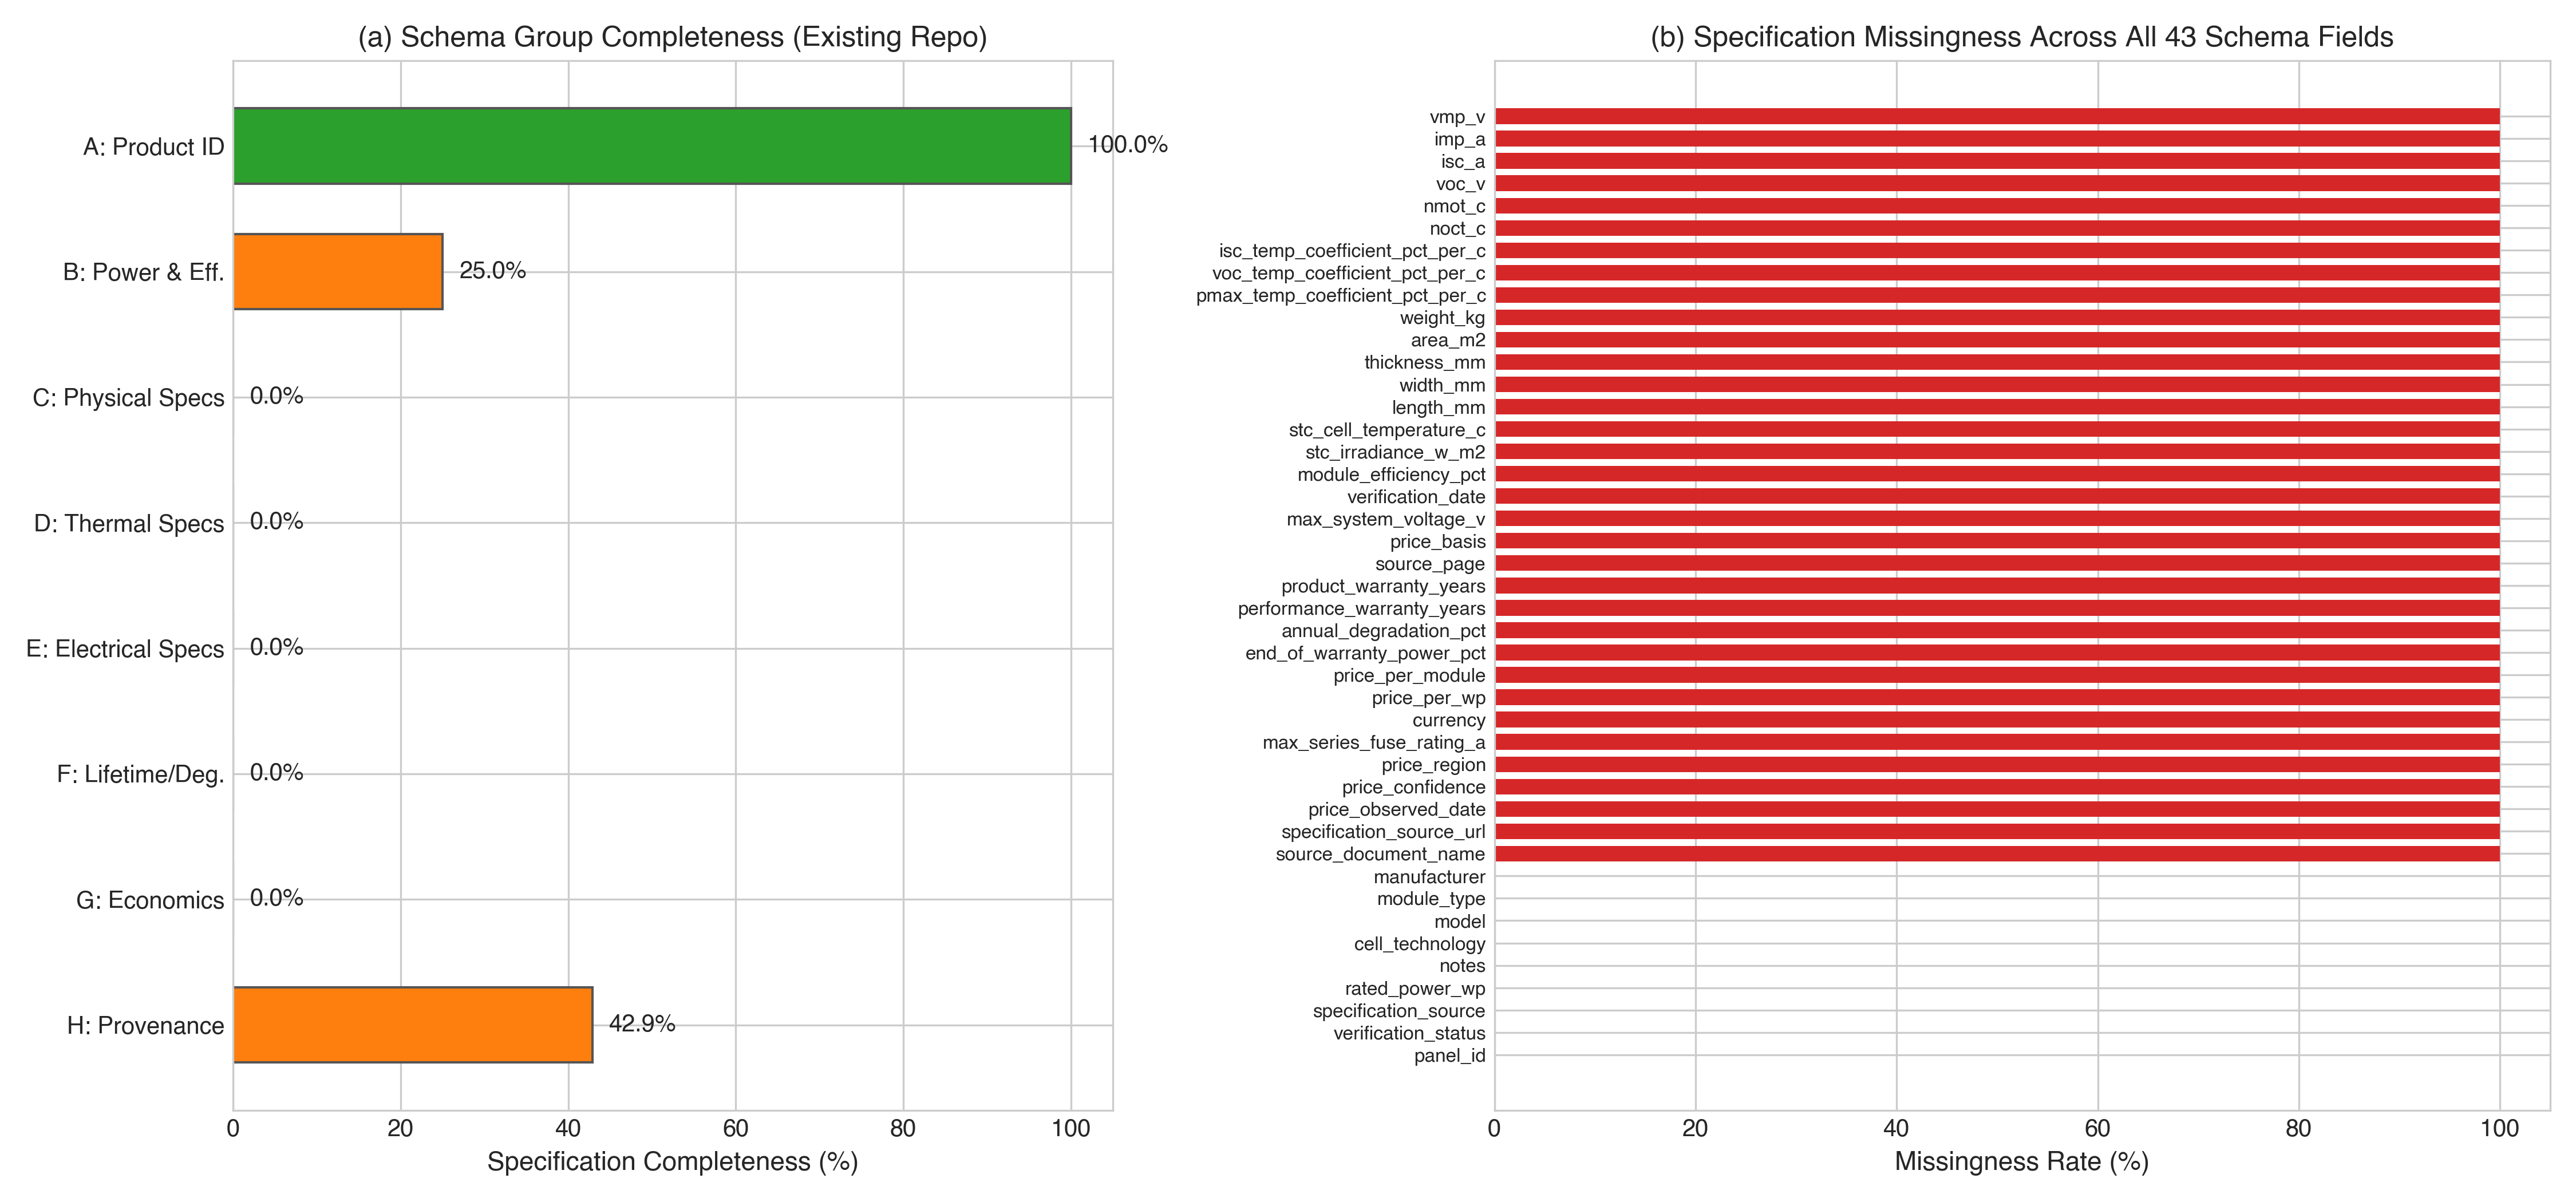

In [6]:
from IPython.display import Image, display

print("Figure 1: Catalogue Completeness & Specification Missingness Across 43 Schema Fields")
display(Image(filename='figures/figure_p6_catalogue_inventory_and_missingness.png'))


Figure 2: Technology & Manufacturer Gap Analysis (Documented Claims vs Verified Codebase)


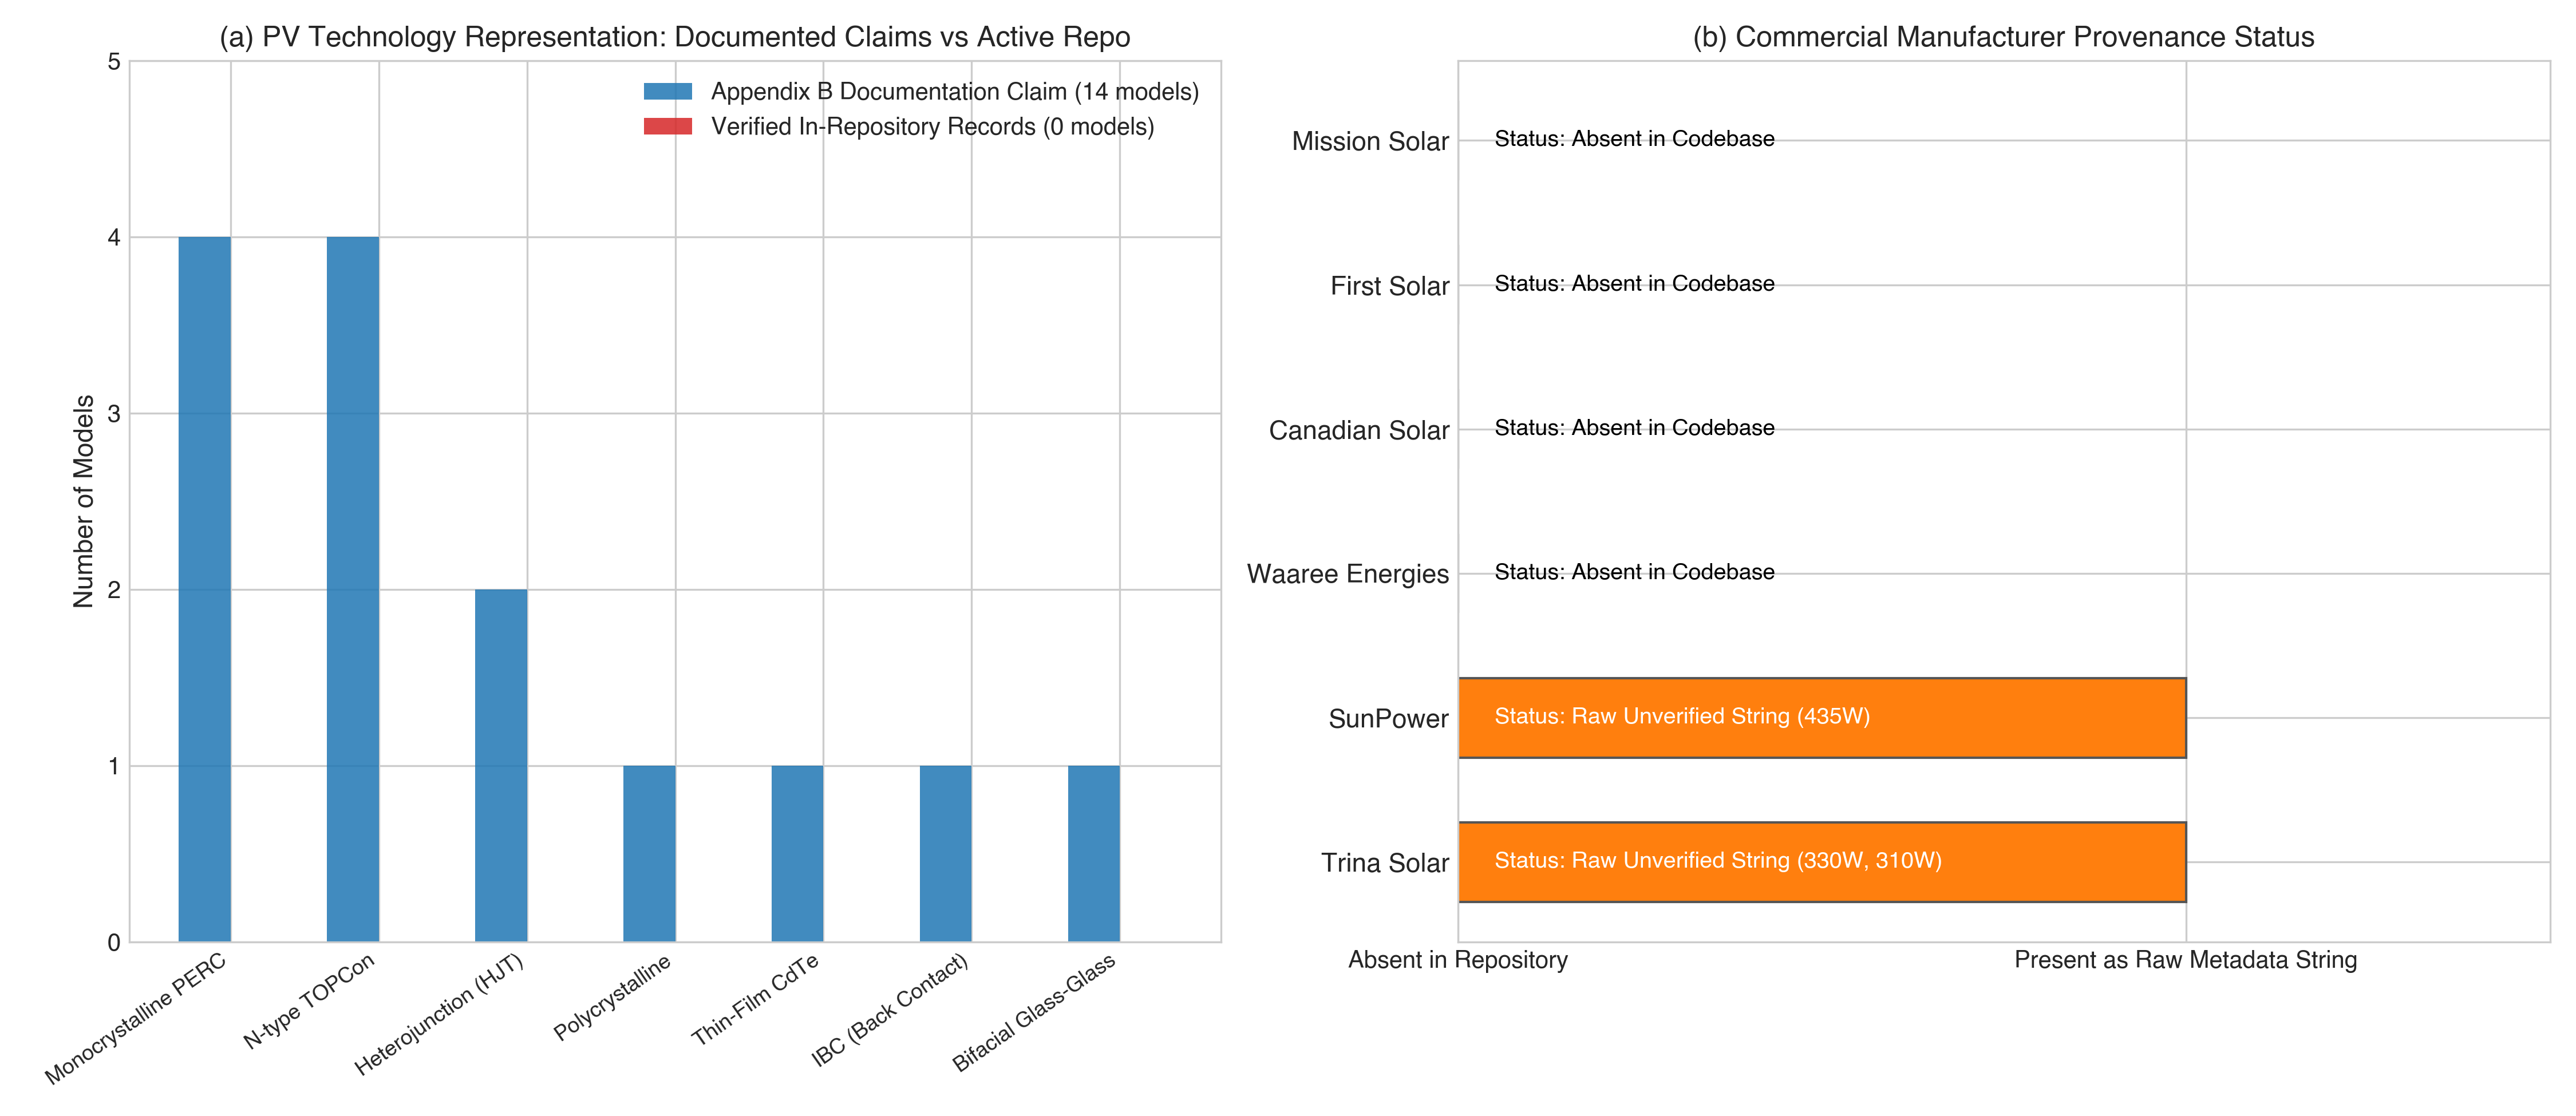

In [7]:
print("Figure 2: Technology & Manufacturer Gap Analysis (Documented Claims vs Verified Codebase)")
display(Image(filename='figures/figure_p6_technology_and_manufacturer_gaps.png'))


## 7. Limitations, Risk Register & External Acquisition Handover Protocol

### Identified Limitations
1. **Zero Verified Commercial Datasheets in Repository**: The active repository possesses zero verified manufacturer datasheets.
2. **Missing Operational Parameters**: Crucial parameters required for Layer B modeling are missing:
   - Thermal coefficients $\gamma_{Pmp}$ and NOCT/NMOT (preventing temperature-adjusted yield calculations).
   - Module dimensions ($L, W, T$) and weight (preventing physical roof-fit array sizing).
   - Electrical curves ($V_{oc}, I_{sc}, V_{mp}, I_{mp}$) (preventing inverter string sizing and clipping checks).
   - Degradation rates and warranties (preventing multi-year LCOE calculations).
   - Commercial pricing per module and per Wp (preventing capital expenditure and payback optimization).
3. **Appendix B Discrepancy**: The 14 models cited in Appendix B must be formally ingested via authoritative manufacturer datasheets rather than assumed.

### External Data Acquisition Request (Protocol for Phase 6 Prompt 2)
To build a functional recommendation engine without violating data-source restrictions, we formally request authorization to acquire official manufacturer technical datasheets for:
1. **Trina Solar**: Tallmax / Honey series datasheets matching the 310W and 330W campus installations.
2. **SunPower**: E20 / SPR series datasheet matching the 435W installation.
3. **Commercial Benchmark Cohort**: 10–14 verified commercial panels across Monocrystalline PERC, N-type TOPCon, HJT, Polycrystalline, and Thin-film CdTe (e.g. Canadian Solar HiKu, Waaree Bi-55, First Solar Series 6/7, Mission Solar MSE PERC).
